# 42c · Project: LQR balance, from a cart-pole to a humanoid
The Linear Quadratic Regulator is the workhorse of balance control: linearize the robot around the pose you want
to hold, choose what you care about (a cost), and get the optimal feedback gain from one matrix equation.

$$\min_u \sum_t x_t^\top Q x_t + u_t^\top R u_t \quad\text{s.t.}\quad x_{t+1} = A x_t + B u_t \qquad\Rightarrow\qquad u_t = -K x_t,\quad K = (R + B^\top P B)^{-1} B^\top P A$$
where $P$ solves the discrete algebraic Riccati equation $P = Q + A^\top P A - A^\top P B (R + B^\top P B)^{-1} B^\top P A$.

MuJoCo gives us $A$ and $B$ directly: `mjd_transitionFD` differentiates one simulation step by finite differences.
No hand-derived equations of motion, for a 2-DoF cart-pole or a 35-DoF humanoid alike.

In [1]:
import numpy as np, matplotlib.pyplot as plt, mujoco
from vlacourse import show_video
from vlacourse import showcase as sc
from vlacourse.lqr import CartPole, G1Balance, linearize, dlqr, wrap

## 1. The cart-pole: linearize, solve, balance
State $x = (\text{cart position}, \text{pole angle}, \text{velocities})$, angle 0 = upright. One input: the force on the cart.

In [2]:
cp = CartPole()
np.set_printoptions(precision=3, suppress=True)
print("A (discrete, 2 ms step):\n", cp.A, "\nB:", cp.B.ravel(), "\nK:", cp.K.ravel())
print("closed-loop eigenvalue magnitudes:", np.abs(np.linalg.eigvals(cp.A - cp.B @ cp.K)).round(4), "(all < 1: stable)")

A (discrete, 2 ms step):
 [[ 1.    -0.     0.002  0.   ]
 [ 0.     1.     0.     0.002]
 [ 0.    -0.005  1.     0.   ]
 [ 0.     0.044  0.001  1.   ]] 
B: [ 0.    -0.     0.002 -0.003] 
K: [ -9.835 -76.626 -11.928 -16.288]
closed-loop eigenvalue magnitudes: [0.986 0.986 0.997 0.997] (all < 1: stable)


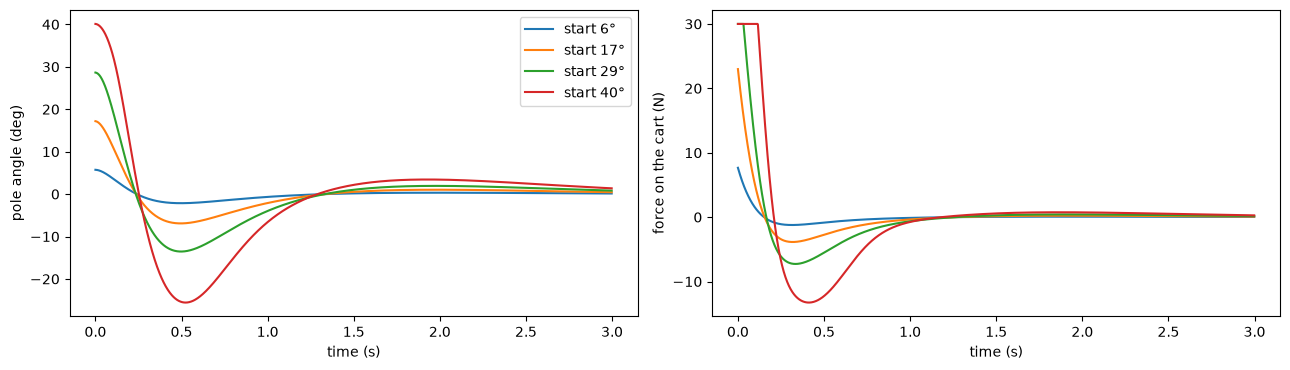

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for th0 in [0.1, 0.3, 0.5, 0.7]:
    cp.set(0, th0); log = []
    for k in range(1500):
        u = cp.lqr_u(); cp.step(u); log.append((k * 0.002, wrap(cp.d.qpos[1]), cp.d.qpos[0], u))
    L = np.array(log)
    ax[0].plot(L[:, 0], np.degrees(L[:, 1]), label=f"start {np.degrees(th0):.0f}°"); ax[1].plot(L[:, 0], L[:, 3])
ax[0].set_ylabel("pole angle (deg)"); ax[1].set_ylabel("force on the cart (N)")
for a in ax: a.set_xlabel("time (s)")
ax[0].legend(); plt.tight_layout(); plt.show()

## 2. Q and R are the design knobs
$R$ prices force; $Q$ prices error. Cheap force → fast, aggressive recovery; expensive force → gentle, slow, and a
smaller set of starting angles it can save (the force limit of 30 N bites earlier).

In [4]:
rows = []
for r in [0.001, 0.01, 0.1, 1.0]:
    c = CartPole(r=r); worst = 0.0
    for th0 in np.arange(0.05, 1.3, 0.05):
        c.set(0, th0)
        for k in range(2500):
            c.step(c.lqr_u())
        if abs(wrap(c.d.qpos[1])) < 0.02 and abs(c.d.qpos[0]) < 1.8:
            worst = th0
        else:
            break
    c.set(0, 0.3); peak = 0; settle = None
    for k in range(2500):
        u = c.lqr_u(); c.step(u); peak = max(peak, abs(u))
        if settle is None and abs(wrap(c.d.qpos[1])) < np.radians(1) and k > 10:
            settle = k * 0.002
    rows.append((r, np.degrees(worst), peak, settle))
    print(f"R = {r:6.3f}: recovers from up to {np.degrees(worst):4.0f}°, peak force {peak:5.1f} N, settles (<1°) after {settle:.2f} s (from 17°)")

R =  0.001: recovers from up to   52°, peak force  30.0 N, settles (<1°) after 0.16 s (from 17°)


R =  0.010: recovers from up to   49°, peak force  23.0 N, settles (<1°) after 0.22 s (from 17°)


R =  0.100: recovers from up to   43°, peak force  13.2 N, settles (<1°) after 0.33 s (from 17°)


R =  1.000: recovers from up to   29°, peak force  10.1 N, settles (<1°) after 0.44 s (from 17°)


## 3. Swing-up: energy pumping, then LQR catches it
LQR only works near the linearization point. To get there from hanging down, pump energy into the pendulum (push the
cart in step with its swing, Åström & Furuta 2000) until it has exactly the energy of standing upright; when it
comes within 20° of upright, switch to LQR. A hybrid controller: exactly how real systems do it.

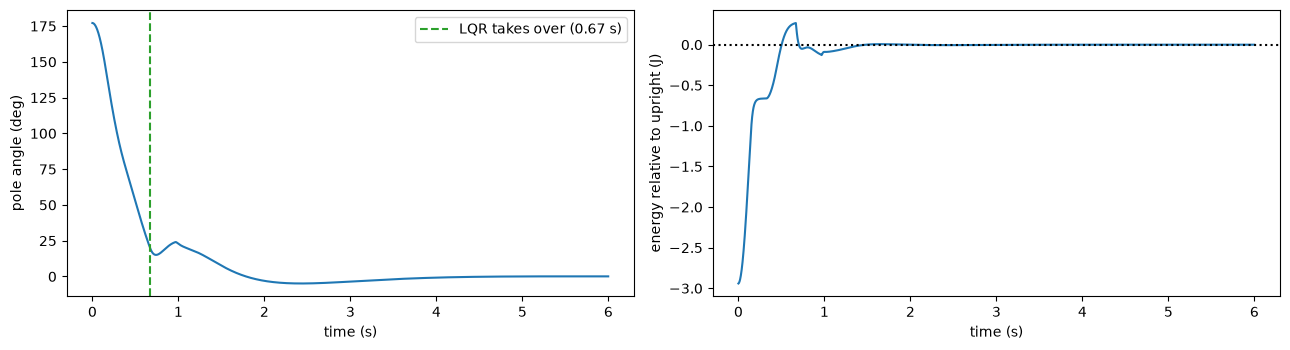

In [5]:
def swing_up(seconds=6.0, film=None):
    cp.set(0, np.pi - 0.05); caught, log, frames = None, [], []
    for k in range(int(seconds / 0.002)):
        th = wrap(cp.d.qpos[1])
        if caught is None and abs(th) < 0.35:
            caught = k * 0.002
        u = cp.lqr_u() if caught is not None else cp.swing_u(40.0)
        cp.step(u); log.append((k * 0.002, th, cp.energy(), u))
        if film is not None and k % 10 == 0:
            frames.append(film(caught))
    return np.array(log), caught, frames

L, caught, _ = swing_up()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(L[:, 0], np.degrees(L[:, 1])); ax[0].axvline(caught, c="tab:green", ls="--", label=f"LQR takes over ({caught:.2f} s)")
ax[0].set_ylabel("pole angle (deg)"); ax[0].legend()
ax[1].plot(L[:, 0], L[:, 2]); ax[1].axhline(0, c="k", ls=":"); ax[1].set_ylabel("energy relative to upright (J)")
for a in ax: a.set_xlabel("time (s)")
plt.tight_layout(); plt.show()

In [6]:
r = mujoco.Renderer(cp.m, 720, 1280); cam = mujoco.MjvCamera()
cam.lookat[:] = [0, 0, 0.1]; cam.distance, cam.azimuth, cam.elevation = 3.2, 90, -12
def cp_frame(caught):
    r.update_scene(cp.d, cam); f = r.render().copy()
    f = sc.caption(f, "cart-pole · energy pumping → LQR", where="top", size=26)
    return sc.badge(f, "LQR balancing" if caught is not None else "swinging up (energy control)", corner="tr", size=22,
                    color=sc.GOOD if caught is not None else sc.ACCENT)
_, _, frames = swing_up(film=cp_frame)
cart_video = sc.title_card("LQR balance", "a cart-pole swings up and balances\nthen a humanoid takes a push", size=(720, 1280), n=60) + frames

## 4. The same recipe on a 35-DoF humanoid
The Unitree G1 (Menagerie) standing on both feet: 29 position-controlled joints plus a free-floating base,
a 70-D state. Following the MuJoCo LQR tutorial:
1. **Set-point:** find the pelvis height where the feet carry exactly the robot's weight, use inverse dynamics to
   get the joint torques that hold that pose, and convert them into the position servos' set-points `ctrl0`.
2. **Linearize** around (pose, ctrl0) with `mjd_transitionFD`: $A$ is 70×70, $B$ is 70×29.
3. **Cost:** a big weight on keeping the centre of mass over the feet (via the CoM Jacobian minus the feet
   Jacobians), moderate weights on the leg and waist joints, small on the arms.
4. $u = \text{ctrl0} - K\,\Delta x$, with $\Delta x$ from `mj_differentiatePos` (quaternions need a proper difference).

**Baseline:** every joint holds its set-point with its own position servo, which is joint-level PD with no
coordination between joints.

In [7]:
g = G1Balance(balance_cost=100.0, r=10.0)
ev = np.abs(np.linalg.eigvals(g.A - g.B @ g.K))
print(f"G1: state {2 * g.m.nv}-D, {g.m.nu} actuators; K is {g.K.shape}")
print(f"closed-loop eigenvalue magnitudes: {np.sum(ev < 0.9999)} of {len(ev)} strictly inside the unit circle, {np.sum(ev >= 0.9999)} at 1.0")
print("  (the ones at 1.0 are where the robot stands on the floor and which way it faces: the cost doesn't care, so")
print("   LQR leaves them alone; a nudge that slides the robot 1 cm is not 'corrected', which is what we want)")

G1: state 70-D, 29 actuators; K is (29, 70)
closed-loop eigenvalue magnitudes: 67 of 70 strictly inside the unit circle, 3 at 1.0
  (the ones at 1.0 are where the robot stands on the floor and which way it faces: the cost doesn't care, so
   LQR leaves them alone; a nudge that slides the robot 1 cm is not 'corrected', which is what we want)


## 5. Push tests: how hard can you shove it?
A 0.1 s push on the torso, 3 s to recover (fallen = pelvis below 0.55 m). Each force is one trial; we sweep forces
in three directions instead of searching for a single threshold (survival isn't perfectly monotonic in force).

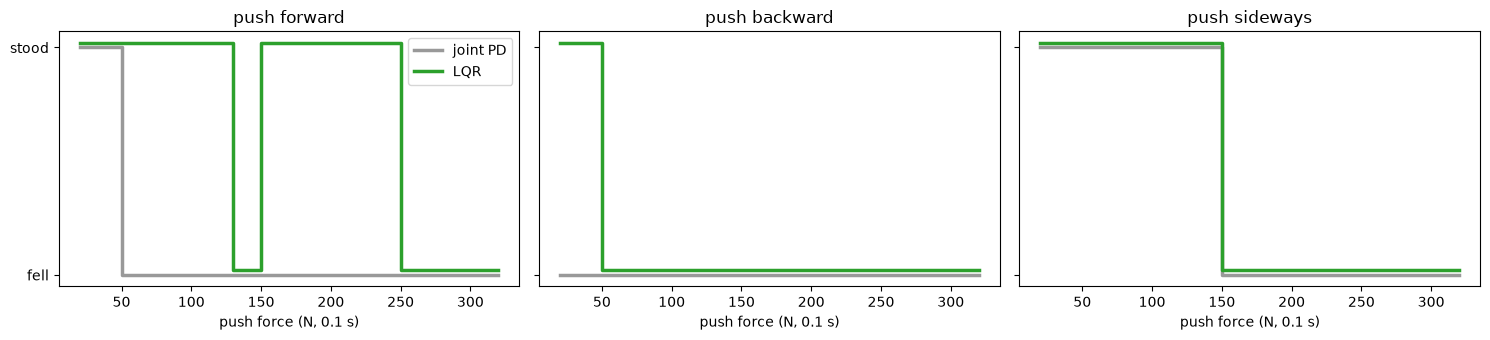

forward   largest push survived: joint PD   40 N  | LQR  240 N  (11/16 vs 2/16 forces survived)
backward  largest push survived: joint PD    0 N  | LQR   40 N  (2/16 vs 0/16 forces survived)
sideways  largest push survived: joint PD  140 N  | LQR  140 N  (7/16 vs 7/16 forces survived)


In [8]:
forces = np.arange(20, 321, 20)
dirs = {"forward": (1, 0, 0), "backward": (-1, 0, 0), "sideways": (0, 1, 0)}
surv = {}
for mode in ["pd", "lqr"]:
    for name, dv in dirs.items():
        surv[(mode, name)] = np.array([g.push_test(f, mode, dv) for f in forces])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for a, name in zip(ax, dirs):
    for mode, c in [("pd", "#999"), ("lqr", "tab:green")]:
        a.step(forces, surv[(mode, name)].astype(int) + (0.02 if mode == "lqr" else 0), where="mid", c=c, lw=2.5, label="joint PD" if mode == "pd" else "LQR")
    a.set_title(f"push {name}"); a.set_xlabel("push force (N, 0.1 s)"); a.set_yticks([0, 1]); a.set_yticklabels(["fell", "stood"])
ax[0].legend(); plt.tight_layout(); plt.show()
for name in dirs:
    pd_max = forces[surv[("pd", name)]].max() if surv[("pd", name)].any() else 0
    lqr_max = forces[surv[("lqr", name)]].max() if surv[("lqr", name)].any() else 0
    print(f"{name:9s} largest push survived: joint PD {pd_max:4.0f} N  | LQR {lqr_max:4.0f} N  ({surv[('lqr', name)].sum()}/{len(forces)} vs {surv[('pd', name)].sum()}/{len(forces)} forces survived)")

Reading it: in the **sagittal plane** (forward/backward) the coordinated LQR response survives several times the push
that independent joint servos do: it moves hips and ankles *together* to put the centre of mass back over the feet
(the "ankle and hip strategies" of human balance). **Sideways**, the wide stance already does most of the work and
both controllers are similar. A single linear controller around a single pose has limits: a hard enough push needs a
*step*, and stepping is beyond LQR: that's where model predictive control and learned policies (S05 53b) come in.

## 6. Share-ready video: the same push, two controllers

In [9]:
gr = mujoco.Renderer(g.m, 720, 640); gcam = mujoco.MjvCamera()
gcam.lookat[:] = [0, 0, 0.75]; gcam.distance, gcam.azimuth, gcam.elevation = 3.0, 140, -12
def g_frame(label):
    def f(bal, t, force):
        gr.update_scene(bal.d, gcam)
        if force > 0:                                              # draw the push as a red arrow at the torso
            sc_ = gr.scene
            if sc_.ngeom < sc_.maxgeom:
                p = bal.d.xpos[bal.m.body("torso_link").id]
                gg = sc_.geoms[sc_.ngeom]
                mujoco.mjv_initGeom(gg, mujoco.mjtGeom.mjGEOM_ARROW, np.zeros(3), np.zeros(3), np.zeros(9), np.array([1, 0.2, 0.2, 1], np.float32))
                mujoco.mjv_connector(gg, mujoco.mjtGeom.mjGEOM_ARROW, 0.03, p - np.array(PUSH_DIR) * 0.5, p - np.array(PUSH_DIR) * 0.08)
                sc_.ngeom += 1
        img = gr.render().copy()
        img = sc.caption(img, label, where="top", size=24)
        return sc.badge(img, f"push {force:.0f} N" if force > 0 else f"t = {t:.1f} s", corner="tr", size=20, color=sc.BAD if force > 0 else sc.ACCENT)
    return f

name = "forward"; PUSH_DIR = dirs[name]
cands = forces[surv[("lqr", name)] & ~surv[("pd", name)]]                # pushes LQR survives and joint PD doesn't
F = int(np.median(cands)) if len(cands) else 80
clips = {}
for mode, label in [("pd", "joint PD (each joint holds its angle)"), ("lqr", "whole-body LQR")]:
    fr = []; ok = g.push_test(F, mode, PUSH_DIR, T=3.0, frames=fr, film=g_frame(label))
    end = sc.badge(fr[-1], "✓ recovered" if ok else "✗ fell", corner="bl", size=28, color=sc.GOOD if ok else sc.BAD)
    clips[mode] = fr + [end] * 40
T = max(len(c) for c in clips.values())
side = [np.hstack([clips[m][min(t, len(clips[m]) - 1)] for m in ("pd", "lqr")]) for t in range(T)]
print(f"video: {F} N push {name}, PD vs LQR")
video = cart_video + side
show_video(video, fps=50, title="42c LQR balance HD", width=960)
sc.export(video, "outputs/42c_lqr_balance.mp4", fps=50)

video: 160 N push forward, PD vs LQR


saved outputs/42c_lqr_balance.mp4  (1.5 MB)


['outputs/42c_lqr_balance.mp4']

## Exercises
1. **Tune the humanoid:** sweep `balance_cost` and `r` (try 30–1000 and 1–100). Plot the survived force per
   direction. Why does making force "cheaper" (small R) not always help? (Hint: torque limits and the linearization.)
2. **One-leg balance:** linearize the G1 standing on one foot (lift the other with the set-point), keep the CoM over
   the stance foot only. How much smaller is the push it survives?
3. **LQR for the drone** (project 42): linearize the X2 at hover, design $K$, and compare its step response with the
   cascaded PID. Which handles the wind gust better?
4. **Region of attraction:** for the cart-pole, map which (angle, angular velocity) starts LQR recovers. Where does
   the 30 N force limit bite?